In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
train = pd.read_csv("Sign Language MNIST/sign_mnist_train.csv")
test = pd.read_csv("Sign Language MNIST/sign_mnist_test.csv")

x_train = train.drop('label', axis=1).values
y_train = train['label'].values

x_test = test.drop('label', axis=1).values
y_test = test['label'].values

x_train = x_train / 255.0
x_test = x_test / 255.0

In [3]:
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(25, activation='softmax')
])

In [4]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=10,
                    validation_data=(x_test, y_test))

Epoch 1/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.3611 - loss: 2.0635 - val_accuracy: 0.5191 - val_loss: 1.5337
Epoch 2/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6185 - loss: 1.1955 - val_accuracy: 0.5863 - val_loss: 1.3333
Epoch 3/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7153 - loss: 0.8845 - val_accuracy: 0.6189 - val_loss: 1.1811
Epoch 4/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7816 - loss: 0.6793 - val_accuracy: 0.6539 - val_loss: 1.1351
Epoch 5/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8341 - loss: 0.5228 - val_accuracy: 0.6751 - val_loss: 1.0985
Epoch 6/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8724 - loss: 0.4075 - val_accuracy: 0.6737 - val_loss: 1.1059
Epoch 7/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9068 - loss: 0.3050 - val_accuracy: 0.7066 - val_loss: 1.0839
Epoch 8/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9351 - loss: 0.2281 - val_accuracy: 0.

In [5]:
model.evaluate(x_test, y_test)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6913 - loss: 1.2531  


[1.2531437873840332, 0.6912994980812073]

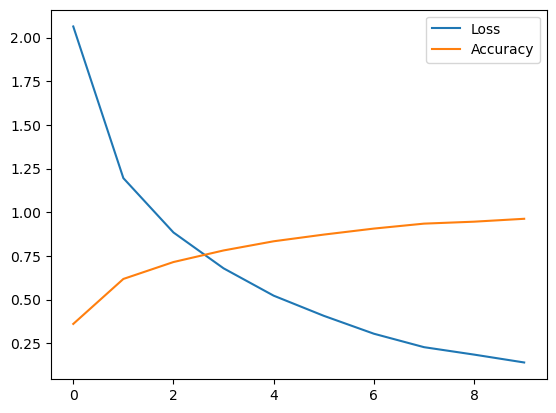

In [6]:
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['accuracy'], label='Accuracy')
plt.legend()
plt.show()